# Conveyor Stoppage Risk with Logistic Regression

Estimate a fictional conveyor's unplanned stoppage risk in the following 24 hours from three prior-inspection measurements.

**Beginner/intermediate learning project. Synthetic data only. AI-assisted implementation.**
Учебный проект начального/среднего уровня, созданный с помощью AI. Данные синтетические.

Run this notebook from its project folder. Read the short Python cells in order; the CSV and generator are included.


## 1. Read the inspection examples
One prior-inspection snapshot per fictional conveyor. / Одна проверка на каждый учебный конвейер. The outcome refers to the next 24 hours.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, precision_score, recall_score

df = pd.read_csv("data/synthetic_data.csv")
print(df.head().to_string(index=False))

 conveyor_id  temperature_c  vibration_mm_s  hours_since_service  stop_next_24h
           1             69            5.99                  454              0
           2             53            8.33                  431              0
           3             75            1.70                  407              0
           4             77            5.03                 1364              1
           5             58            2.66                  570              0


## 2. Inspect the sensor data with Pandas
Describe the sensors and compare historical averages. / Смотрим статистику датчиков и средние значения. This is descriptive analysis, not proof of cause.


In [2]:
print(df[["temperature_c", "vibration_mm_s", "hours_since_service"]].describe().round(2).to_string())
summary = df.groupby("stop_next_24h")[["temperature_c", "vibration_mm_s"]].mean()
print(summary.round(2).to_string())

       temperature_c  vibration_mm_s  hours_since_service
count         240.00          240.00               240.00
mean           72.53            6.56               719.57
std            16.17            3.08               408.15
min            45.00            1.10                22.00
25%            59.75            3.87               377.25
50%            71.00            6.57               773.50
75%            88.00            9.28              1055.25
max           100.00           11.96              1398.00
               temperature_c  vibration_mm_s
stop_next_24h                               
0                      70.25            5.52
1                      76.31            8.29


## 3. Hold out independent conveyors
Hold out 25% of conveyor IDs; each conveyor appears only once. / Откладываем 25% конвейеров для проверки.


In [3]:
X = df[["temperature_c", "vibration_mm_s", "hours_since_service"]]
y = df["stop_next_24h"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

## 4. Put different sensor units on a comparable scale
Temperature, vibration and hours use different units, so scale them using training data only. / Единицы измерения разные: приводим их к сопоставимому масштабу по обучающим данным.


In [4]:
# Learn the scaling from training data only; reuse it on test data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 5. Train a model that returns a probability
Despite its name, logistic regression solves a classification problem here. / Логистическая регрессия здесь решает задачу классификации. The 0.50 threshold is fixed, not chosen on test data.


In [5]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
probability = model.predict_proba(X_test_scaled)[:, 1]
predicted = (probability >= 0.50).astype(int)

## 6. Compare probability errors and inspect alerts
Compare with predicting the training stoppage rate for every conveyor. / Сравниваем с постоянным риском, равным доле остановок в обучении. Review both false alarms and missed stoppages.


In [6]:
baseline = [y_train.mean()] * len(y_test)
print(f"Model Brier score: {brier_score_loss(y_test, probability):.3f}")
print(f"Baseline Brier score: {brier_score_loss(y_test, baseline):.3f}")
print(f"Alert precision: {precision_score(y_test, predicted, zero_division=0):.3f}")
print(f"Stoppage recall: {recall_score(y_test, predicted, zero_division=0):.3f}")
print("Brier score measures probability error; lower is better.")
results = pd.DataFrame({"conveyor_id": df.loc[X_test.index, "conveyor_id"], "observed_stop": y_test, "risk": probability})
print(results.sort_values("risk", ascending=False).head().round(3).to_string(index=False))

Model Brier score: 0.188
Baseline Brier score: 0.232
Alert precision: 0.625
Stoppage recall: 0.455
Brier score measures probability error; lower is better.
 conveyor_id  observed_stop  risk
         209              1 0.928
         133              1 0.918
         127              1 0.892
         165              1 0.882
          62              1 0.853


## 7. Estimate risk for one new inspection
Use exactly the same scaler for a new inspection. / Для нового примера применяем тот же scaler. The engineer decides what to inspect; this model cannot operate or stop equipment.


Illustrative next-24-hour stoppage risk: 64.2%


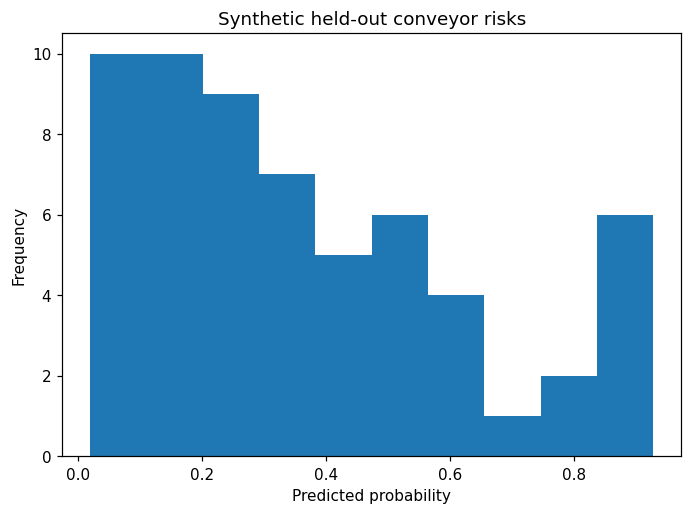

In [7]:
new_inspection = pd.DataFrame({"temperature_c": [85], "vibration_mm_s": [8], "hours_since_service": [900]})
new_scaled = scaler.transform(new_inspection)
risk = model.predict_proba(new_scaled)[0, 1]
print(f"Illustrative next-24-hour stoppage risk: {risk:.1%}")
results["risk"].plot.hist(bins=10, title="Synthetic held-out conveyor risks")
plt.xlabel("Predicted probability")
plt.tight_layout()
plt.savefig("results/evaluation.png")

## What I need to explain / Что нужно уметь объяснить

1. What each CSV column means.
2. Which information is known before prediction.
3. What `fit` and `predict` do.
4. Why we keep test data separate.
5. Whether this model beats its baseline, and what the errors mean.

These small synthetic test sets do not establish real-world accuracy. No real savings or company deployment are claimed. A real pilot needs approved historical records, forward-time validation and an engineer/planner responsible for decisions.
